In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import os

BASE_DIR = os.path.dirname(os.getcwd())

train_path = os.path.join(BASE_DIR, "dataset", "sign_mnist_train.csv")
test_path = os.path.join(BASE_DIR, "dataset", "sign_mnist_test.csv")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training dataset loaded:", train_df.shape)
print("Testing dataset loaded:", test_df.shape)

Training dataset loaded: (27455, 785)
Testing dataset loaded: (7172, 785)


In [5]:
print(train_df.shape)
print(test_df.shape)
print(train_df.head())

(27455, 785)
(7172, 785)
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      3     107     118     127     134     139     143     146     150   
1      6     155     157     156     156     156     157     156     158   
2      2     187     188     188     187     187     186     187     188   
3      2     211     211     212     212     211     210     211     210   
4     13     164     167     170     172     176     179     180     184   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0     153  ...       207       207       207       207       206       206   
1     158  ...        69       149       128        87        94       163   
2     187  ...       202       201       200       199       198       199   
3     210  ...       235       234       233       231       230       226   
4     185  ...        92       105       105       108       133       163   

   pixel781  pixel782  pixel783  pixel784  
0    

In [6]:
print("Dataset Information:")
print(train_df.info())

print("\nMissing Values:")
print(train_df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(train_df.duplicated().sum())

print("\nLabel Distribution:")
print(train_df["label"].value_counts().sort_index())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 27455 entries, 0 to 27454
Columns: 785 entries, label to pixel784
dtypes: int64(785)
memory usage: 164.4 MB
None

Missing Values:
0

Duplicate Rows:
0

Label Distribution:
label
0     1126
1     1010
2     1144
3     1196
4      957
5     1204
6     1090
7     1013
8     1162
10    1114
11    1241
12    1055
13    1151
14    1196
15    1088
16    1279
17    1294
18    1199
19    1186
20    1161
21    1082
22    1225
23    1164
24    1118
Name: count, dtype: int64


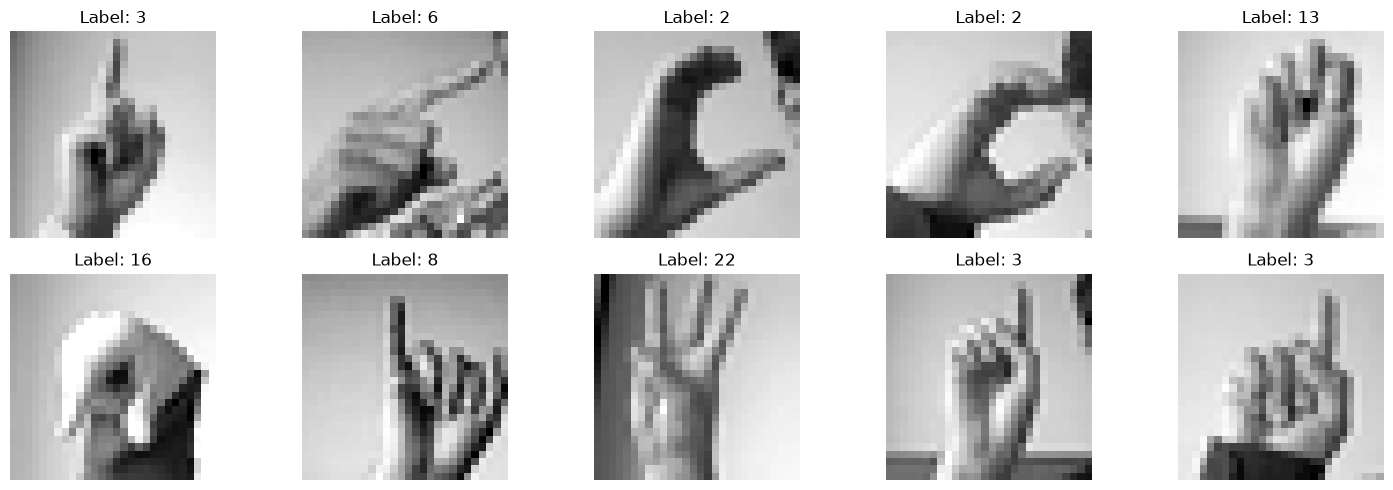

In [7]:
# Separate labels and pixel values
labels = train_df["label"]
images = train_df.drop("label", axis=1)

# Display 10 sample images
plt.figure(figsize=(15, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = images.iloc[i].values.reshape(28, 28)

    plt.imshow(image, cmap="gray")
    plt.title(f"Label: {labels.iloc[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
X_train = train_df.drop("label", axis=1).values
y_train = train_df["label"].values

X_test = test_df.drop("label", axis=1).values
y_test = test_df["label"].values

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training data shape: (27455, 784)
Testing data shape: (7172, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training image shape:", X_train.shape)
print("Testing image shape:", X_test.shape)

Training image shape: (27455, 28, 28, 1)
Testing image shape: (7172, 28, 28, 1)


In [10]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training image shape:", X_train.shape)
print("Testing image shape:", X_test.shape)

Training image shape: (27455, 28, 28, 1)
Testing image shape: (7172, 28, 28, 1)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (21964, 28, 28, 1)
Validation: (5491, 28, 28, 1)
Testing: (7172, 28, 28, 1)


In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [13]:
model = Sequential([

    # First convolution block
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),

    MaxPooling2D((2, 2)),

    # Second convolution block
    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    # Classification layers
    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(24, activation='softmax')
])

model.summary()

c:\Users\Nayana\ASL_Trainer\venv312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [17]:
# Shift labels greater than 9 down by 1
y_train = np.where(y_train > 9, y_train - 1, y_train)
y_val = np.where(y_val > 9, y_val - 1, y_val)
y_test = np.where(y_test > 9, y_test - 1, y_test)

In [18]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [19]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Epoch 1/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.5307 - loss: 1.5423 - val_accuracy: 0.8907 - val_loss: 0.4338
Epoch 2/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8762 - loss: 0.3838 - val_accuracy: 0.9814 - val_loss: 0.1083
Epoch 3/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9516 - loss: 0.1639 - val_accuracy: 0.9978 - val_loss: 0.0338
Epoch 4/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9759 - loss: 0.0870 - val_accuracy: 0.9995 - val_loss: 0.0116
Epoch 5/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.9857 - loss: 0.0528 - val_accuracy: 0.9998 - val_loss: 0.0070
Epoch 6/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9884 - loss: 0.0422 - val_accuracy: 1.0000 - val_loss: 0.0033
Epoch 7/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9912 - loss: 0.0325 - val_accuracy: 1.0000 - val_loss: 0.0027
Epoch 8/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9924 - loss: 0.0261 - val_acc

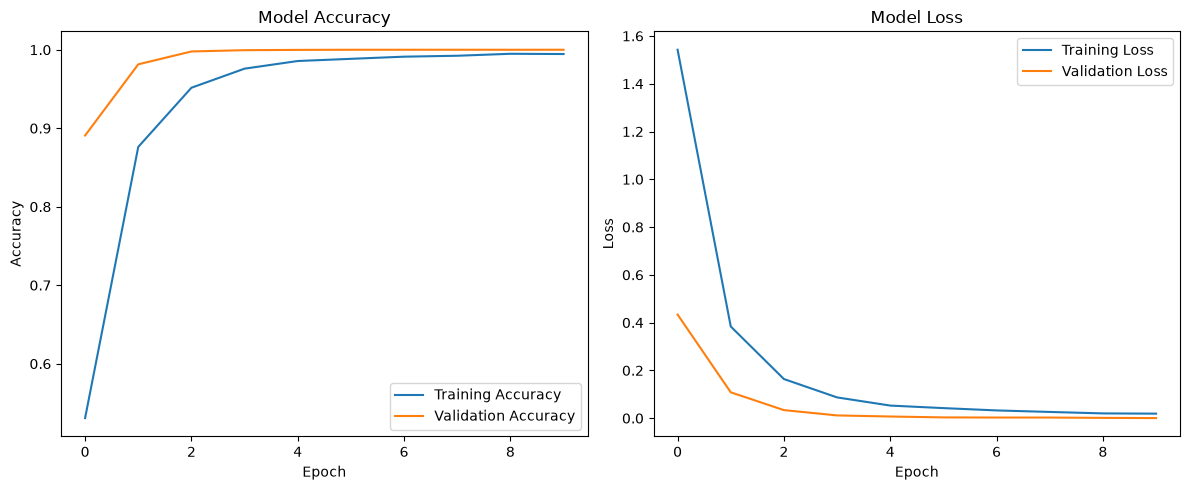

In [20]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9347 - loss: 0.2572
Test Loss: 0.25717422366142273
Test Accuracy: 93.47462058067322 %


225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


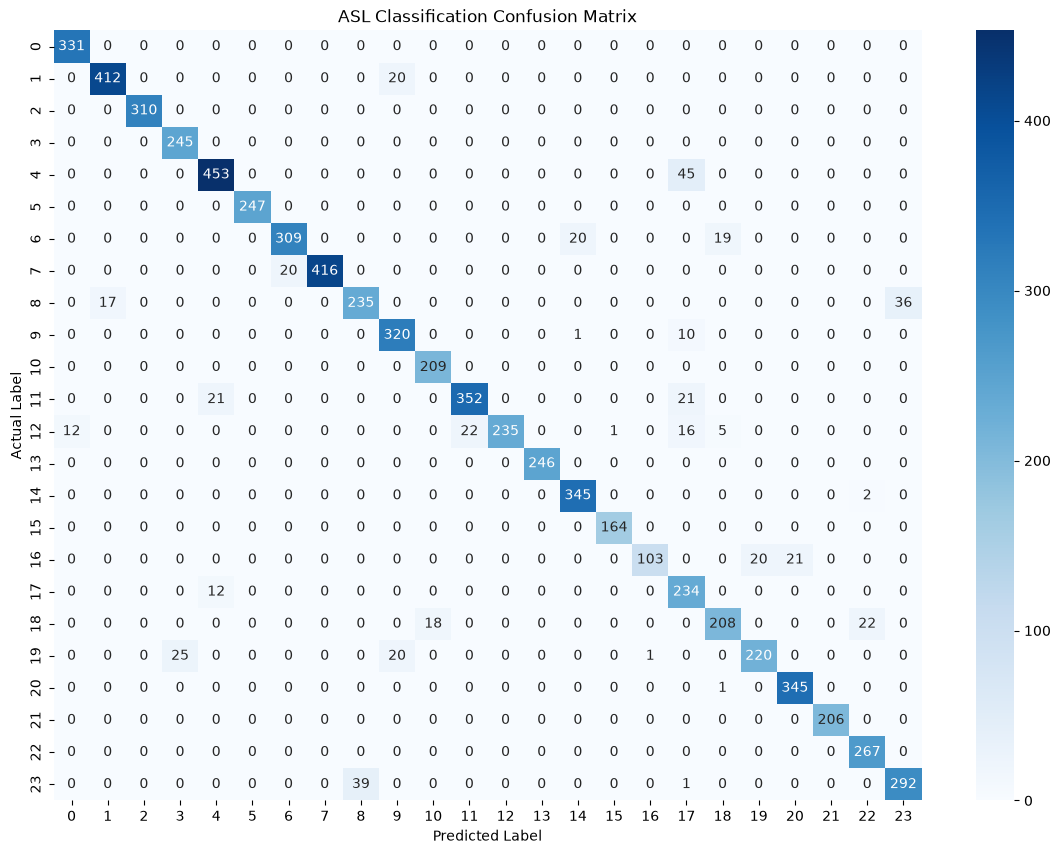

              precision    recall  f1-score   support

           0       0.97      1.00      0.98       331
           1       0.96      0.95      0.96       432
           2       1.00      1.00      1.00       310
           3       0.91      1.00      0.95       245
           4       0.93      0.91      0.92       498
           5       1.00      1.00      1.00       247
           6       0.94      0.89      0.91       348
           7       1.00      0.95      0.98       436
           8       0.86      0.82      0.84       288
           9       0.89      0.97      0.93       331
          10       0.92      1.00      0.96       209
          11       0.94      0.89      0.92       394
          12       1.00      0.81      0.89       291
          13       1.00      1.00      1.00       246
          14       0.94      0.99      0.97       347
          15       0.99      1.00      1.00       164
          16       0.99      0.72      0.83       144
          17       0.72    

In [22]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Generate predictions
y_pred = np.argmax(model.predict(X_test), axis=1)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("ASL Classification Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# Classification report
print(classification_report(y_test, y_pred))